# Ethereum NFT Transaction Value Analysis

An exploratory portfolio project using SQL, pandas, visualization and machine learning to study historical Ethereum NFT transfers. The target is transaction value in ETH, a proxy rather than a verified individual sale price. See the README for dataset and evaluation limitations.

In [1]:
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Fontconfig error: No writable cache directories
Fontconfig error: No writable cache directories


Fontconfig error: No writable cache directories


Matplotlib is building the font cache; this may take a moment.


In [2]:
import os
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
DB_PATH = Path(os.environ.get("NFT_DB_PATH", str(ROOT / "data" / "nfts.sqlite"))).expanduser().resolve()
if not DB_PATH.is_file():
    raise FileNotFoundError("Set NFT_DB_PATH to your downloaded nfts.sqlite file; see data/README.md")
REPORTS = ROOT / "reports"
ARTIFACTS = ROOT / "artifacts"
REPORTS.mkdir(exist_ok=True)
ARTIFACTS.mkdir(exist_ok=True)


In [3]:
conn = sqlite3.connect(DB_PATH.as_uri() + "?mode=ro", uri=True)

## 1. Load and inspect the data

Use a fixed 100,000-row, positive-value sample in SQLite row order. This preserves the original sample design; it is not random or representative of the full market.

In [4]:

#To inspect the database tables

tables = pd.read_sql_query("""
SELECT name
FROM sqlite_master
WHERE type = 'table';
""", conn)

tables

,name
0,nfts
1,checkpoint
2,mints
3,transfers
4,transfer_values_quartile_10_distribution_per_a...
5,current_owners
6,current_market_values
7,market_values_distribution
8,transfer_statistics_by_address
9,transfer_values_quantile_10_distribution_per_a...


In [5]:
#lets create a smaller modelling table to find out factors that could possibly affect nft prices 

model_data = pd.read_sql_query("""
SELECT *
FROM transfers
WHERE transaction_value > 0
ORDER BY rowid
LIMIT 100000;
""", conn)

model_data.shape


(100000, 9)

In [6]:
#we are checking for the columns in the table

columns = pd.read_sql_query("PRAGMA table_info(transfers);", conn)
columns[["name", "type"]]

,name,type
0,event_id,TEXT
1,transaction_hash,TEXT
2,block_number,INTEGER
3,nft_address,TEXT
4,token_id,TEXT
5,from_address,TEXT
6,to_address,TEXT
7,transaction_value,INTEGER
8,timestamp,INTEGER


In [7]:
tables


,name
0,nfts
1,checkpoint
2,mints
3,transfers
4,transfer_values_quartile_10_distribution_per_a...
5,current_owners
6,current_market_values
7,market_values_distribution
8,transfer_statistics_by_address
9,transfer_values_quantile_10_distribution_per_a...


In [8]:
model_data.columns.tolist()

['event_id',
 'transaction_hash',
 'block_number',
 'nft_address',
 'token_id',
 'from_address',
 'to_address',
 'transaction_value',
 'timestamp']

## 2. Engineer activity features

Convert wei to ETH and Unix timestamps to UTC, then construct calendar and observed transfer-history features.

In [9]:
#convert the traget variable from wei to eth
model_data["price_eth"] = (
    pd.to_numeric(model_data["transaction_value"], errors="coerce") / 1e18
)

In [10]:
y = model_data["price_eth"]

In [11]:
#create the independent variables that may help explain NFT prices. These columns were not part of the original dataset, so we must engineer them.

model_data["timestamp"] = pd.to_datetime(
    pd.to_numeric(
    model_data["timestamp"],
    errors="coerce",
),

unit="s",
    errors="coerce",
    utc=True
)

model_data = model_data.sort_values(["timestamp", "event_id"], kind="stable").reset_index(drop=True)

model_data["year"] = model_data["timestamp"].dt.year
model_data["month"] = model_data["timestamp"].dt.month
model_data["day_of_week"] = model_data["timestamp"].dt.dayofweek
model_data["hour"] = model_data["timestamp"].dt.hour


model_data["collection_activity"] = (
    model_data.groupby("nft_address").cumcount()
)

model_data["token_transfer_count"] = (
    model_data.groupby(["nft_address", "token_id"]).cumcount()
)

model_data["seller_activity"] = (
    model_data.groupby("from_address").cumcount()
)

model_data["buyer_activity"] = (
    model_data.groupby("to_address").cumcount()
)


import numpy as np

features = [
    "block_number",
    "year",
    "month",
    "day_of_week",
    "hour",
    "collection_activity",
    "token_transfer_count",
    "seller_activity",
    "buyer_activity"
]

model_df = model_data[features + ["price_eth"]].copy()

model_df = model_df.replace([np.inf, -np.inf], np.nan)
model_df = model_df.dropna()
model_df = model_df[model_df["price_eth"] > 0]

In [12]:
# define the independent and dependent variables
X = model_df[features]       # Independent variables
y = model_df["price_eth"]    # Dependent/target variable

In [13]:
#lets see if it works 

print("X shape:", X.shape)
print("y shape:", y.shape)

model_df.head()

In [14]:
model_data[["transaction_value", "price_eth"]].head()

In [15]:
#we will determine the price distributions 
print("X shape:", X.shape)
print("y shape:", y.shape)

model_df.head()

In [16]:
#we will examine the number of rows and columns in the table

print("Number of rows:", model_data.shape[0])
print("Number of columns:", model_data.shape[1])

model_data.head()

In [17]:
model_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 18 columns):
 #   Column                Non-Null Count   Dtype              
---  ------                --------------   -----              
 0   event_id              100000 non-null  object             
 1   transaction_hash      100000 non-null  object             
 2   block_number          100000 non-null  int64              
 3   nft_address           100000 non-null  object             
 4   token_id              100000 non-null  object             
 5   from_address          100000 non-null  object             
 6   to_address            100000 non-null  object             
 7   transaction_value     100000 non-null  float64            
 8   timestamp             100000 non-null  datetime64[ns, UTC]
 9   price_eth             100000 non-null  float64            
 10  year                  100000 non-null  int32              
 11  month                 100000 non-null  int32         

## 3. Data quality and price distribution

Inspect missingness, duplicates and outliers. Positive-value filtering does not prove every record is a sale.

In [18]:
#lets check for missing values
#first we will convert blank text into missing values
model_data_clean=model_data.copy()
text_columns=model_data_clean.select_dtypes(
    include=["object", "string"]
).columns

model_data_clean[text_columns]=model_data_clean[
    text_columns
].replace(r"^\s*$", np.nan, regex=True)

In [19]:
#lets generate a complete missing values report 
missing_report = pd.DataFrame({
    "data_type": model_data_clean.dtypes.astype(str),
    "missing_count": model_data_clean.isna().sum(),
    "missing_percentage": (
        model_data_clean.isna().mean() * 100
    ).round(2)
})

missing_report = missing_report.sort_values(
    "missing_percentage",
    ascending=False
)

missing_report

,data_type,missing_count,missing_percentage
event_id,object,0,0.0
transaction_hash,object,0,0.0
seller_activity,int64,0,0.0
token_transfer_count,int64,0,0.0
collection_activity,int64,0,0.0
hour,int32,0,0.0
day_of_week,int32,0,0.0
month,int32,0,0.0
year,int32,0,0.0
price_eth,float64,0,0.0


In [20]:
#this is to check if we still have missing values in the table
missing_report[
    missing_report["missing_count"] > 0
]

,data_type,missing_count,missing_percentage


In [21]:
#lets check for duplicate rows 
duplicate_rows = model_data_clean.duplicated().sum()

print("Exact duplicate rows:", duplicate_rows)

Exact duplicate rows: 0


In [22]:
#lets check if event_id is uniquehub
print("Total rows:", len(model_data_clean))
print("Unique event IDs:", model_data_clean["event_id"].nunique())
print(
    "Duplicated event IDs:",
    model_data_clean["event_id"].duplicated().sum()
)

Total rows: 100000
Unique event IDs: 100000
Duplicated event IDs: 0


In [23]:
#lets examine the target variable 
model_data_clean["price_eth"].describe(
    percentiles=[0.01, 0.25, 0.50, 0.75, 0.95, 0.99]
)

count    1.000000e+05
mean     7.422507e-01
std      3.426428e+00
min      1.025000e-09
1%       2.142600e-03
25%      6.000000e-02
50%      1.800000e-01
75%      4.500000e-01
95%      2.700000e+00
99%      1.100100e+01
max      4.690000e+02
Name: price_eth, dtype: float64

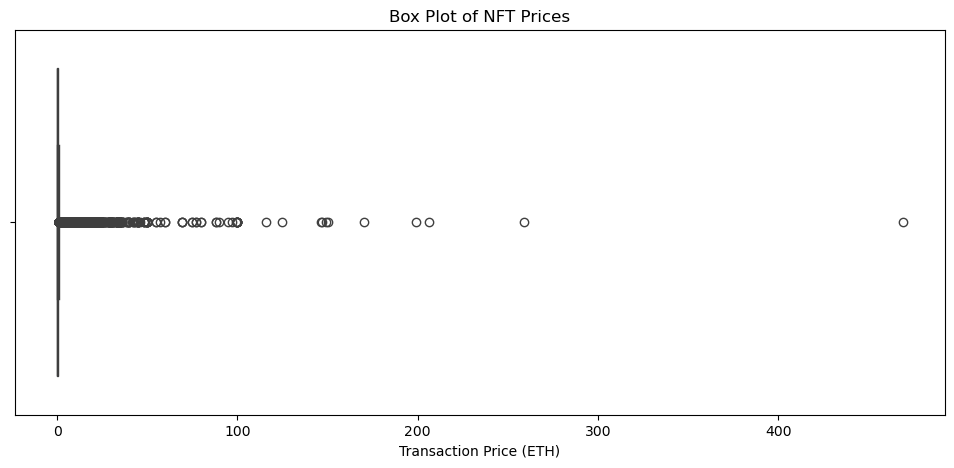

In [24]:
#lets check for outliers with a box plot

plt.figure(figsize=(12,5))

sns.boxplot(
    x=model_data_clean["price_eth"]
)
plt.title("Box Plot of NFT Prices")
plt.xlabel("Transaction Price (ETH)")
plt.show()

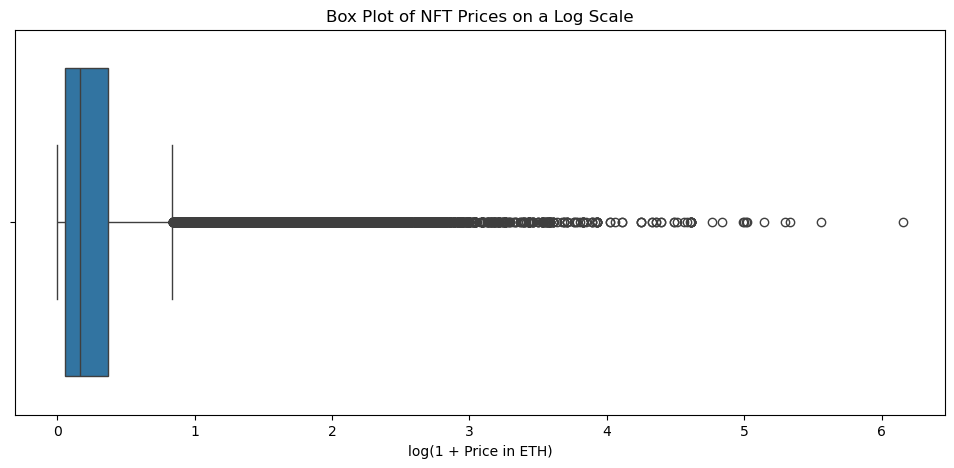

In [25]:
#we will use logarithmic values for a better view since this is compressed 
import numpy as np

plt.figure(figsize=(12, 5))

sns.boxplot(
    x=np.log1p(model_data_clean["price_eth"])
)

plt.title("Box Plot of NFT Prices on a Log Scale")
plt.xlabel("log(1 + Price in ETH)")
plt.show()

In [26]:
#we will count the outliers
Q1 = model_data_clean["price_eth"].quantile(0.25)
Q3 = model_data_clean["price_eth"].quantile(0.75)
IQR = Q3 - Q1

upper_limit = Q3 + (1.5 * IQR)

outliers = model_data_clean[
    model_data_clean["price_eth"] > upper_limit
]

print("Upper outlier limit:", upper_limit, "ETH")
print("Number of outliers:", len(outliers))
print(
    "Percentage of outliers:",
    round(len(outliers) / len(model_data_clean) * 100, 2),
    "%"
)

Upper outlier limit: 1.035 ETH
Number of outliers: 11905
Percentage of outliers: 11.91 %


In [27]:
#lets examine the largest transactions 
outliers[
    [
        "transaction_hash",
        "nft_address",
        "token_id",
        "price_eth",
        "timestamp"
    ]
].sort_values(
    "price_eth",
    ascending=False
).head(20)

In [28]:
#keep genuine outliers and transform the target
analysis_data = model_data_clean[
    model_data_clean["price_eth"] > 0
].copy()

analysis_data["log_price_eth"] = np.log1p(
    analysis_data["price_eth"]
)

In [29]:
y = analysis_data["log_price_eth"]

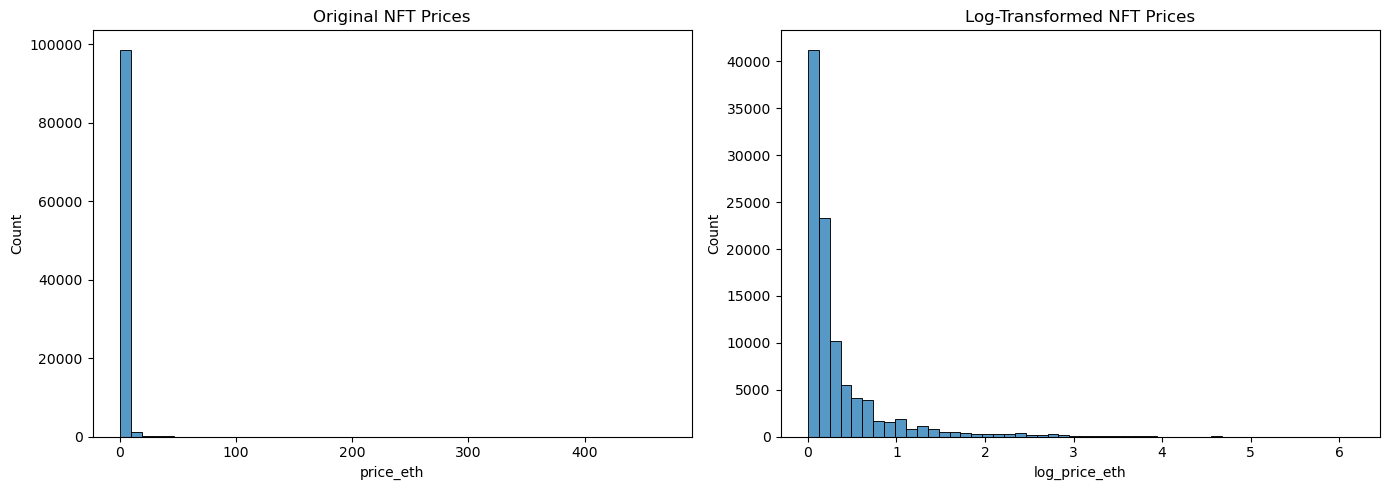

In [30]:
#here we confirm the transformation

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    analysis_data["price_eth"],
    bins=50,
    ax=axes[0]
)
axes[0].set_title("Original NFT Prices")

sns.histplot(
    analysis_data["log_price_eth"],
    bins=50,
    ax=axes[1]
)
axes[1].set_title("Log-Transformed NFT Prices")

plt.tight_layout()
plt.show()

## 4. Explore associations

Compare activity, calendar patterns and log transaction value.

In [31]:
#we will calculate the continous independent variables

continuous_features = [
    "block_number",
    "collection_activity",
    "token_transfer_count",
    "seller_activity",
    "buyer_activity"
]

In [32]:
#lets calculate both pearson and spearman correlation
correlation_results = pd.DataFrame({
    "Pearson": analysis_data[
        continuous_features
    ].corrwith(analysis_data["log_price_eth"], method="pearson"),

    "Spearman": analysis_data[
        continuous_features
    ].corrwith(analysis_data["log_price_eth"], method="spearman")
})

correlation_results = correlation_results.sort_values(
    "Spearman",
    key=abs,
    ascending=False
)

correlation_results.round(3)

,Pearson,Spearman
collection_activity,0.065,0.235
seller_activity,-0.110,-0.190
token_transfer_count,0.080,0.122
block_number,-0.062,-0.073
buyer_activity,-0.033,0.018


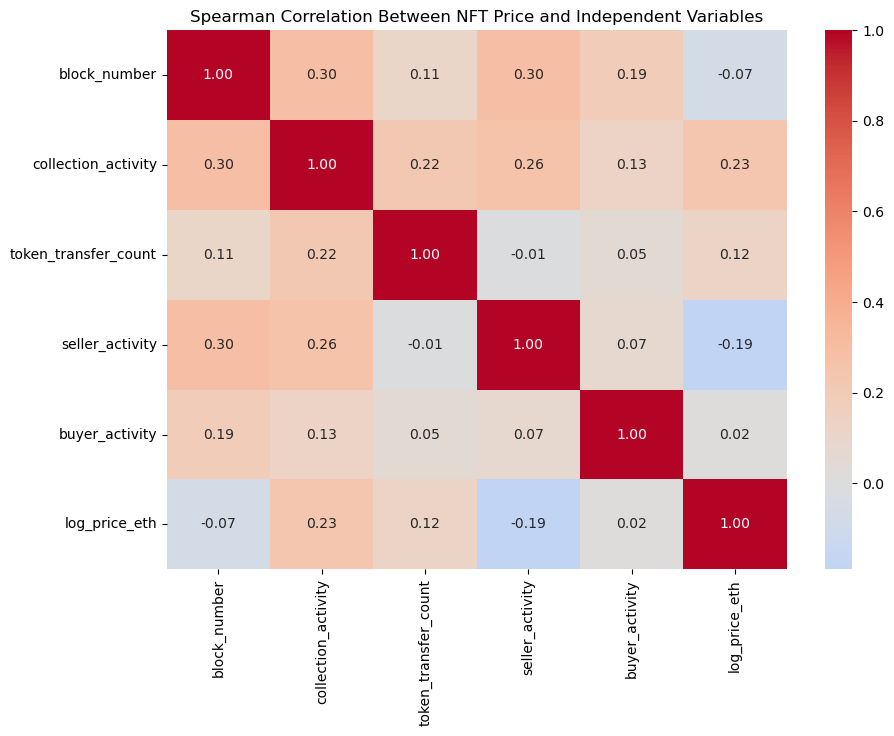

In [33]:
#lets plot a correlation heatmap
correlation_columns = continuous_features + ["log_price_eth"]

plt.figure(figsize=(10, 7))

sns.heatmap(
    analysis_data[correlation_columns].corr(method="spearman"),
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)

plt.title("Spearman Correlation Between NFT Price and Independent Variables")
plt.show()

In [34]:
# Lets create a scatter plot to show how each numerical variable relates to nft price 
#create plotting sample 
plot_sample = analysis_data.sample(
    n=min(10000, len(analysis_data)),
    random_state=42
).copy()

In [35]:
#lets create logarithmic versions of activity variables so heavily clustered counts are easier to see
activity_features = [
    "collection_activity",
    "token_transfer_count",
    "seller_activity",
    "buyer_activity"
]

for column in activity_features:
    plot_sample["log_" + column] = np.log1p(
        plot_sample[column]
    )

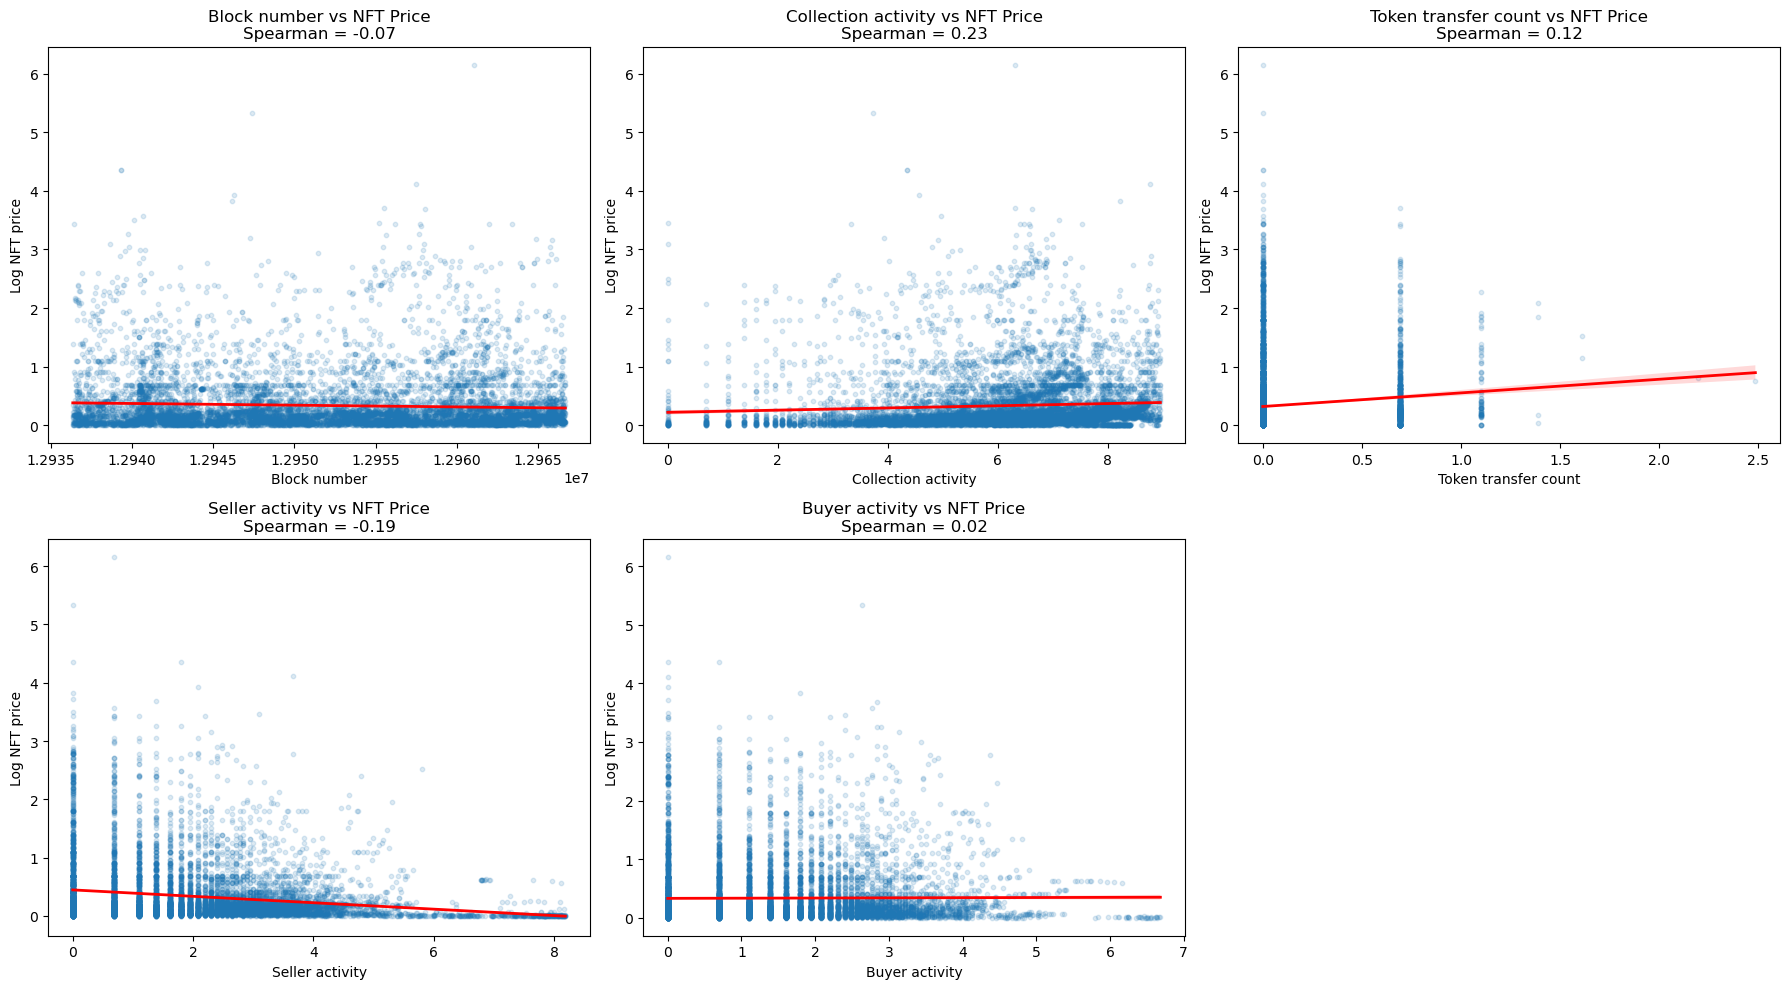

In [36]:
#lets create the scatter plots 
plot_variables = [
    ("block_number", "Block number", "block_number"),
    (
        "log_collection_activity",
        "Collection activity",
        "collection_activity"
    ),
    (
        "log_token_transfer_count",
        "Token transfer count",
        "token_transfer_count"
    ),
    (
        "log_seller_activity",
        "Seller activity",
        "seller_activity"
    ),
    (
        "log_buyer_activity",
        "Buyer activity",
        "buyer_activity"
    )
]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for axis, (plot_column, label, original_column) in zip(
    axes,
    plot_variables
):
    correlation = analysis_data[
        [original_column, "log_price_eth"]
    ].corr(method="spearman").iloc[0, 1]

    sns.regplot(
        data=plot_sample,
        x=plot_column,
        y="log_price_eth",
        scatter_kws={
            "alpha": 0.15,
            "s": 10
        },
        line_kws={
            "color": "red",
            "linewidth": 2
        },
        ax=axis
    )

    axis.set_title(
        f"{label} vs NFT Price\nSpearman = {correlation:.2f}"
    )
    axis.set_xlabel(label)
    axis.set_ylabel("Log NFT price")

# Hide the unused sixth panel
axes[5].axis("off")

plt.tight_layout()
plt.show()

Activity plots describe associations in this sample. They do not establish whether activity causes changes in transaction value.

In [37]:
#Lets compare NFT prices across time periods 
year_summary = (
    analysis_data.groupby("year", as_index=False)
    .agg(
        median_price=("price_eth", "median"),
        transactions=("price_eth", "size")
    )
)

month_summary = (
    analysis_data.groupby("month", as_index=False)
    .agg(
        median_price=("price_eth", "median"),
        transactions=("price_eth", "size")
    )
)

day_summary = (
    analysis_data.groupby("day_of_week", as_index=False)
    .agg(
        median_price=("price_eth", "median"),
        transactions=("price_eth", "size")
    )
)

hour_summary = (
    analysis_data.groupby("hour", as_index=False)
    .agg(
        median_price=("price_eth", "median"),
        transactions=("price_eth", "size")
    )
)

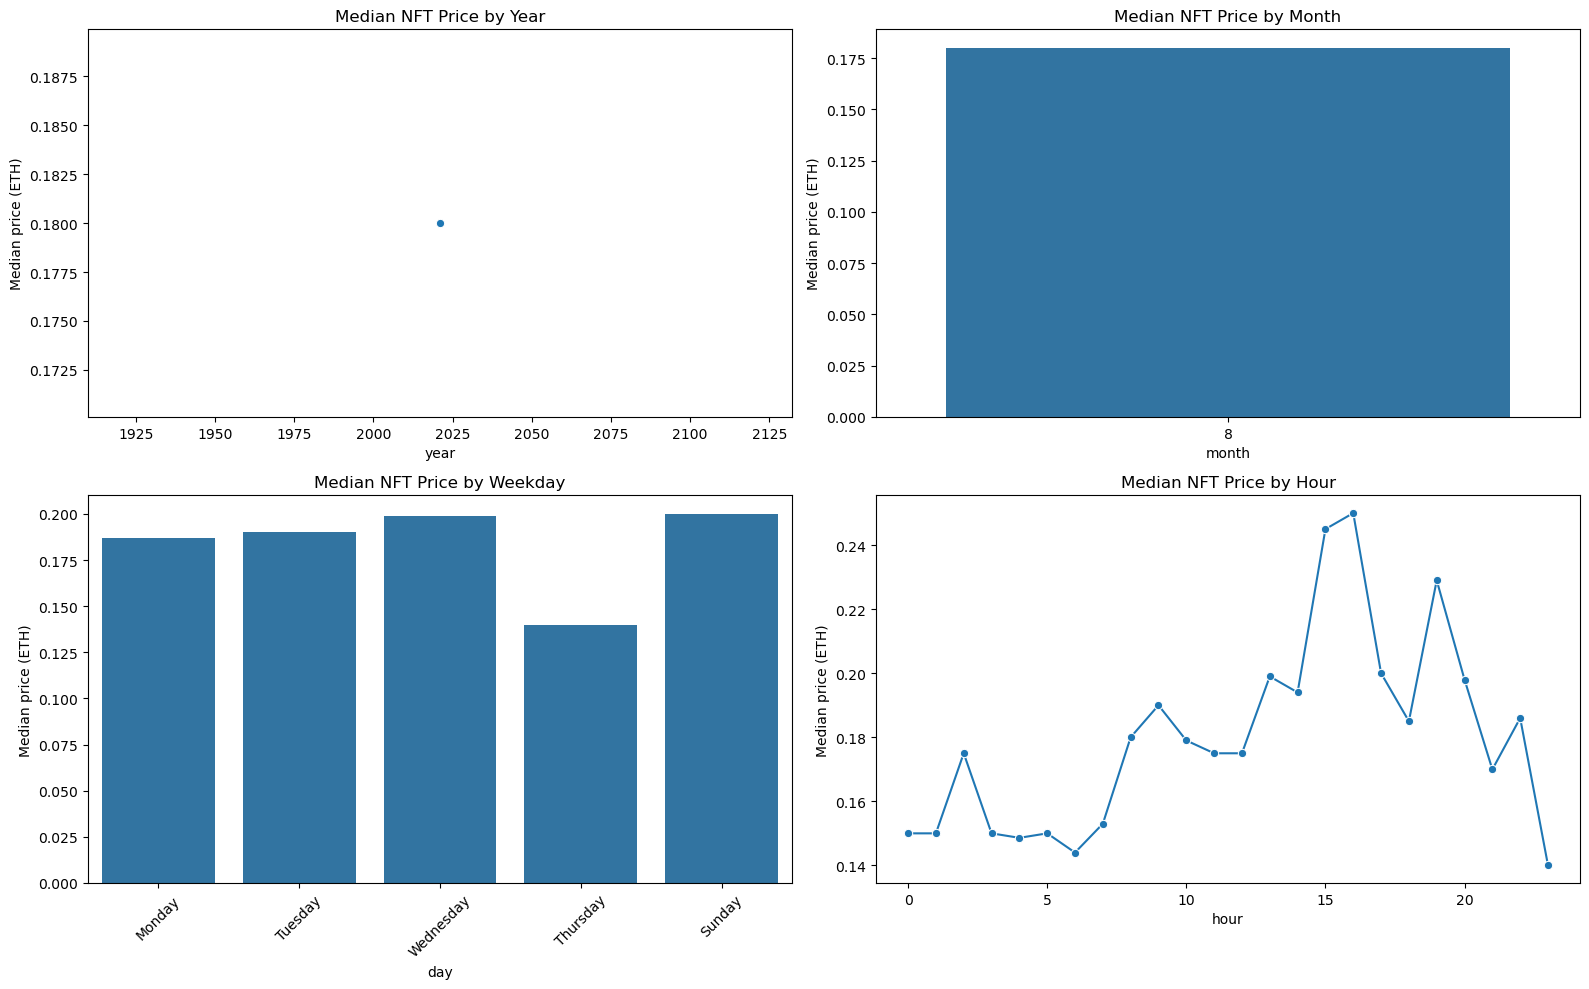

In [38]:
#Lets create the comparison plots 
day_names={
    0:"Monday",
    1:"Tuesday",
    2:"Wednesday",
    3:"Thursday",
    4:"Friday",
    5:"Saturday",
    6:"Sunday"
}

day_summary["day"]=day_summary["day_of_week"].map(day_names)
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
sns.lineplot(
    data=year_summary,
    x="year",
    y="median_price",
    marker="o",
    ax=axes[0, 0]
)
axes[0, 0].set_title("Median NFT Price by Year")
axes[0, 0].set_ylabel("Median price (ETH)")

sns.barplot(
    data=month_summary,
    x="month",
    y="median_price",
    ax=axes[0, 1]
)
axes[0, 1].set_title("Median NFT Price by Month")
axes[0, 1].set_ylabel("Median price (ETH)")

sns.barplot(
    data=day_summary,
    x="day",
    y="median_price",
    ax=axes[1, 0]
)
axes[1, 0].set_title("Median NFT Price by Weekday")
axes[1, 0].tick_params(axis="x", rotation=45)
axes[1, 0].set_ylabel("Median price (ETH)")

sns.lineplot(
    data=hour_summary,
    x="hour",
    y="median_price",
    marker="o",
    ax=axes[1, 1]
)
axes[1, 1].set_title("Median NFT Price by Hour")
axes[1, 1].set_ylabel("Median price (ETH)")

plt.tight_layout()
plt.show()
    

## 5. Historical price features

Bundle size is counted within the sample, not the complete database. Historical features follow timestamp/event-ID row order; IDs do not establish within-block chronology. Treat results as exploratory.

In [39]:
#Lets check if target represents one NFT
enhanced_data = (
    analysis_data
    .sort_values(["timestamp", "event_id"])
    .reset_index(drop=True)
    .copy()
)


enhanced_data["bundle_size"] = (
    enhanced_data.groupby("transaction_hash")["event_id"]
    .transform("size")
)


single_nft_data = enhanced_data[
    enhanced_data["bundle_size"] == 1
].copy()

print("All transactions:", len(enhanced_data))
print("Single-NFT transactions:", len(single_nft_data))

In [40]:
#lets analyze more direct price related features 
enhanced_data = enhanced_data.sort_values(
    ["timestamp", "event_id"]
).reset_index(drop=True)

enhanced_data["previous_token_price_eth"] = (
    enhanced_data.groupby(
        ["nft_address", "token_id"]
    )["price_eth"].shift(1)
)


enhanced_data["previous_token_log_price"] = np.log1p(
    enhanced_data["previous_token_price_eth"]
)

In [41]:
enhanced_data["previous_token_log_price"] = np.log1p(
    enhanced_data["previous_token_price_eth"]
)

In [42]:
enhanced_data[
    [
        "nft_address",
        "token_id",
        "price_eth",
        "previous_token_price_eth",
        "previous_token_log_price"
    ]
].head(20)

In [43]:
print(
    "Transactions with a previous token price:",
    enhanced_data["previous_token_price_eth"].notna().sum()
)

print(
    "Transactions without a previous token price:",
    enhanced_data["previous_token_price_eth"].isna().sum()
)

Transactions with a previous token price: 8592
Transactions without a previous token price: 91408


In [44]:
important_features = [
    "previous_token_log_price",
    "previous_token_transfers",
    "days_since_previous_transfer",
    "token_age_days",
    "bundle_size",
    "collection_previous_avg_log_price",
    "seller_previous_avg_log_price",
    "buyer_previous_avg_log_price"
]

In [45]:
import numpy as np

# Ensure transactions are arranged chronologically
enhanced_data = enhanced_data.sort_values(
    ["timestamp", "event_id"]
).reset_index(drop=True)

# Group transactions belonging to the same NFT
token_group = enhanced_data.groupby(
    ["nft_address", "token_id"],
    sort=False
)

# Number of times the token was transferred before this transaction
enhanced_data["previous_token_transfers"] = (
    token_group.cumcount()
)

# Timestamp of the token's previous transfer
previous_timestamp = token_group["timestamp"].shift(1)

# Days since the token's previous transfer
enhanced_data["days_since_previous_transfer"] = (
    enhanced_data["timestamp"] - previous_timestamp
).dt.total_seconds() / 86400

# Days since the token first appeared in this dataset
first_timestamp = token_group["timestamp"].transform("min")

enhanced_data["token_age_days"] = (
    enhanced_data["timestamp"] - first_timestamp
).dt.total_seconds() / 86400

In [46]:
#lets create columns for the new important features 


historical_groups = {
    "nft_address": "collection_previous_avg_log_price",
    "from_address": "seller_previous_avg_log_price",
    "to_address": "buyer_previous_avg_log_price"
}

for group_column, new_column in historical_groups.items():

    grouped = enhanced_data.groupby(
        group_column,
        sort=False
    )

    previous_count = grouped.cumcount()

    previous_sum = (
        grouped["log_price_eth"].cumsum()
        - enhanced_data["log_price_eth"]
    )

    enhanced_data[new_column] = (
        previous_sum
        / previous_count.replace(0, np.nan)
    )

In [47]:
#lets check their spearman correlation to price_eth
historical_correlations = (
    enhanced_data[important_features + ["log_price_eth"]]
    .corr(method="spearman")["log_price_eth"]
    .drop("log_price_eth")
    .sort_values(key=abs, ascending=False)
)

historical_correlations

previous_token_log_price             0.807414
collection_previous_avg_log_price    0.802251
buyer_previous_avg_log_price         0.648451
seller_previous_avg_log_price        0.584809
days_since_previous_transfer         0.262655
token_age_days                       0.154997
previous_token_transfers             0.121510
bundle_size                          0.035881
Name: log_price_eth, dtype: float64

## 6. Chronological model comparison

Use an 80/20 row split. Historical test features incorporate outcomes from earlier test rows, representing sequential updates rather than a fixed-horizon forecast. Same-timestamp rows can cross the split.

In [48]:
#Lets prepare the modelling dataset 
model_features = [
    "block_number",
    "collection_activity",
    "seller_activity",
    "buyer_activity",
    "previous_token_log_price",
    "previous_token_transfers",
    "days_since_previous_transfer",
    "token_age_days",
    "collection_previous_avg_log_price",
    "seller_previous_avg_log_price",
    "buyer_previous_avg_log_price"
]

model_df = (
    enhanced_data[
        enhanced_data["bundle_size"] == 1
    ]
    .sort_values(["timestamp", "event_id"], kind="stable")
    .copy()
)

X = model_df[model_features]
y = model_df["log_price_eth"]

print("X shape:", X.shape)
print("y shape:", y.shape)


In [49]:
#Split the data for testing chronologically
split_point = int(len(model_df) * 0.8)

X_train = X.iloc[:split_point]
X_test = X.iloc[split_point:]

y_train = y.iloc[:split_point]
y_test = y.iloc[split_point:]

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 75924
Testing rows: 18981


In [50]:
#Lets create a baseline model this will be compared to the linear regression 
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score


# Baseline model
baseline_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", DummyRegressor(strategy="median"))
])

baseline_model.fit(X_train, y_train)

baseline_predictions = baseline_model.predict(X_test)

baseline_mae = mean_absolute_error(
    y_test,
    baseline_predictions
)

baseline_r2 = r2_score(
    y_test,
    baseline_predictions
)


# Linear regression model
linear_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_test)

linear_mae = mean_absolute_error(
    y_test,
    linear_predictions
)

linear_r2 = r2_score(
    y_test,
    linear_predictions
)




In [51]:
#Build the Linear Regression model
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

linear_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

In [52]:
#lets train the model
linear_model.fit(X_train, y_train)

,steps,"[('imputer', ...), ('scaler', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,missing_values,nan
,strategy,'median'
,fill_value,None
,copy,True
,add_indicator,False
,keep_empty_features,False
,copy,True


In [53]:
#Predict test-set prices
linear_predictions = linear_model.predict(X_test)

In [54]:
from sklearn.metrics import mean_absolute_error, r2_score

linear_mae = mean_absolute_error(
    y_test,
    linear_predictions
)

linear_r2 = r2_score(
    y_test,
    linear_predictions
)

print("Linear Regression MAE:", linear_mae)
print("Linear Regression R²:", linear_r2)

Linear Regression MAE: 0.11467671302708918
Linear Regression R²: 0.6798972991059927


In [55]:
#lets compare with the baseline
# Compare both models
comparison = pd.DataFrame({
    "Model": [
        "Baseline Model",
        "Linear Regression"
    ],
    "MAE": [
        baseline_mae,
        linear_mae
    ],
    "R²": [
        baseline_r2,
        linear_r2
    ]
})

comparison

,Model,MAE,R²
0,Baseline Model,0.195345,-0.035098
1,Linear Regression,0.114677,0.679897


In [56]:
#Lets interprete and diagnose the linear regression
#first examine the feature coeffecient 
coefficient_results = pd.DataFrame({
    "Feature": model_features,
    "Coefficient": linear_model.named_steps["model"].coef_
})

coefficient_results["Absolute_coefficient"] = (
    coefficient_results["Coefficient"].abs()
)

coefficient_results = coefficient_results.sort_values(
    "Absolute_coefficient",
    ascending=False
)

coefficient_results

,Feature,Coefficient,Absolute_coefficient
8,collection_previous_avg_log_price,0.342228,0.342228
10,buyer_previous_avg_log_price,0.085260,0.085260
9,seller_previous_avg_log_price,0.038793,0.038793
4,previous_token_log_price,0.029017,0.029017
1,collection_activity,-0.011660,0.011660
0,block_number,0.007181,0.007181
3,buyer_activity,0.006280,0.006280
2,seller_activity,-0.006220,0.006220
7,token_age_days,0.006198,0.006198
5,previous_token_transfers,0.001096,0.001096


In [57]:
#lets analyze the residuals 
residuals = y_test - linear_predictions

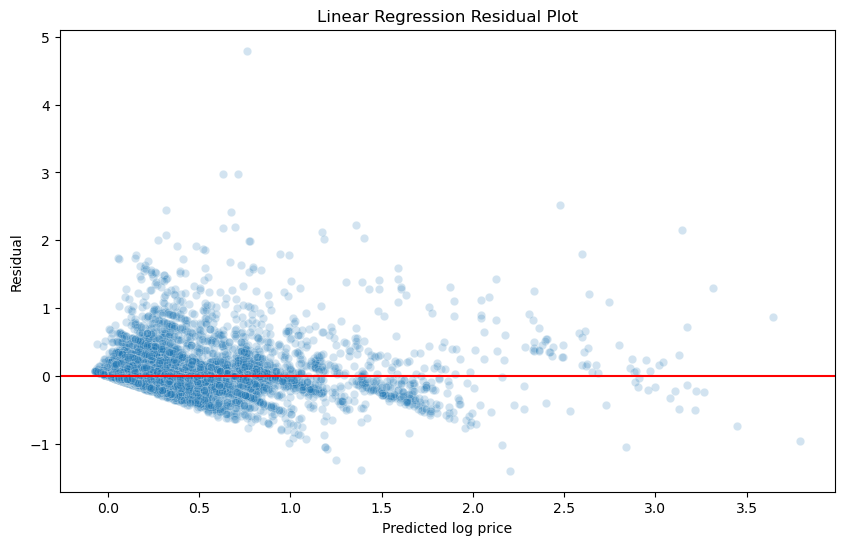

In [58]:
#Lets plot predicted values against the residuals 
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=linear_predictions,
    y=residuals,
    alpha=0.2
)

plt.axhline(0, color="red")
plt.title("Linear Regression Residual Plot")
plt.xlabel("Predicted log price")
plt.ylabel("Residual")
plt.show()

In [59]:
#lets create a random forest regressor since the linear regression doesnt cover the full pricing pattern
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

random_forest_model = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "model",
        RandomForestRegressor(
            n_estimators=150,
            max_depth=18,
            min_samples_leaf=5,
            random_state=42,
            n_jobs=2
        )
    )
])



In [60]:
random_forest_model.fit(
    X_train,
    y_train
)
random_forest_predictions=(
    random_forest_model.predict(X_test)
)

In [61]:
random_forest_mae = mean_absolute_error(
    y_test,
    random_forest_predictions
)

random_forest_r2 = r2_score(
    y_test,
    random_forest_predictions
)

print("Random Forest MAE:", random_forest_mae)
print("Random Forest R-squared:", random_forest_r2)

Random Forest MAE: 0.11797174787812828
Random Forest R-squared: 0.6868483659483459


In [62]:
#lets compare all there models 
model_comparison = pd.DataFrame({
    "Model": [
        "Baseline Model",
        "Linear Regression",
        "Random Forest"
    ],
    "MAE": [
        baseline_mae,
        linear_mae,
        random_forest_mae
    ],
    "R_squared": [
        baseline_r2,
        linear_r2,
        random_forest_r2
    ]
})

model_comparison.sort_values("MAE")

,Model,MAE,R_squared
1,Linear Regression,0.114677,0.679897
2,Random Forest,0.117972,0.686848
0,Baseline Model,0.195345,-0.035098


In [63]:
#lets examine the random forest feature importance 
feature_importance = pd.DataFrame({
    "Feature": model_features,
    "Importance": (
        random_forest_model
        .named_steps["model"]
        .feature_importances_
    )
})

feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
)

feature_importance

,Feature,Importance
8,collection_previous_avg_log_price,0.794329
10,buyer_previous_avg_log_price,0.066195
1,collection_activity,0.046350
0,block_number,0.030576
9,seller_previous_avg_log_price,0.028062
3,buyer_activity,0.013984
2,seller_activity,0.011243
4,previous_token_log_price,0.008053
6,days_since_previous_transfer,0.000566
7,token_age_days,0.000554


In [64]:
#Lets Calculate performance on both training and testing data to check for overfitting

rf_train_predictions = random_forest_model.predict(X_train)

rf_train_mae = mean_absolute_error(
    y_train,
    rf_train_predictions
)

rf_train_r2 = r2_score(
    y_train,
    rf_train_predictions
)

overfitting_check = pd.DataFrame({
    "Dataset": ["Training", "Testing"],
    "MAE": [rf_train_mae, random_forest_mae],
    "R_squared": [rf_train_r2, random_forest_r2]
})

overfitting_check

,Dataset,MAE,R_squared
0,Training,0.083282,0.861298
1,Testing,0.117972,0.686848


## 7. Tune and select the forest

Twelve random configurations, three time-series folds, and a fixed random seed. Select the final forest using training-data CV MAE. Holdout comparisons remain descriptive.

In [65]:
#Lets tune the random forest
from sklearn.model_selection import (
    RandomizedSearchCV,
    TimeSeriesSplit
)

from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

rf_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "model",
        RandomForestRegressor(
            random_state=42,
            n_jobs=1
        )
    )
])

#lets define the settings to test 
parameter_options = {
    "model__n_estimators": [100, 150, 200, 300],
    "model__max_depth": [8, 12, 16, 20, None],
    "model__min_samples_leaf": [2, 5, 10, 20],
    "model__min_samples_split": [2, 5, 10, 20],
    "model__max_features": ["sqrt", 0.7, 1.0]
}

time_split = TimeSeriesSplit(n_splits=3)

rf_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=parameter_options,
    n_iter=12,
    scoring="neg_mean_absolute_error",
    cv=time_split,
    random_state=42,
    n_jobs=2,
    verbose=1
)

rf_search.fit(X_train, y_train)

Fitting 3 folds for each of 12 candidates, totalling 36 fits


,estimator,Pipeline(step...m_state=42))])
,param_distributions,"{'model__max_depth': [8, 12, ...], 'model__max_features': ['sqrt', 0.7, ...], 'model__min_samples_leaf': [2, 5, ...], 'model__min_samples_split': [2, 5, ...], ...}"
,n_iter,12
,scoring,'neg_mean_absolute_error'
,n_jobs,2
,refit,True
,cv,TimeSeriesSpl...est_size=None)
,verbose,1
,pre_dispatch,'2*n_jobs'
,random_state,42
,error_score,nan


In [66]:
#lets view the best settings
print("Best settings:")
print(rf_search.best_params_)

print(
    "Best cross-validation MAE:",
    -rf_search.best_score_
)

Best settings:
{'model__n_estimators': 200, 'model__min_samples_split': 5, 'model__min_samples_leaf': 5, 'model__max_features': 0.7, 'model__max_depth': 8}
Best cross-validation MAE: 0.12325882922895996


In [67]:
#Lets evaluate the tuned model
tuned_random_forest = rf_search.best_estimator_

tuned_test_predictions = tuned_random_forest.predict(
    X_test
)

tuned_rf_mae = mean_absolute_error(
    y_test,
    tuned_test_predictions
)

tuned_rf_r2 = r2_score(
    y_test,
    tuned_test_predictions
)

print("Tuned Random Forest MAE:", tuned_rf_mae)
print("Tuned Random Forest R-squared:", tuned_rf_r2)

Tuned Random Forest MAE: 0.107617270889003
Tuned Random Forest R-squared: 0.7036831273877958


In [68]:
#Lets compare the original and the tuned models 
tuning_comparison = pd.DataFrame({
    "Model": [
        "Original Random Forest",
        "Tuned Random Forest"
    ],
    "MAE": [
        random_forest_mae,
        tuned_rf_mae
    ],
    "R_squared": [
        random_forest_r2,
        tuned_rf_r2
    ]
})

tuning_comparison

,Model,MAE,R_squared
0,Original Random Forest,0.117972,0.686848
1,Tuned Random Forest,0.107617,0.703683


In [69]:
#lets check the tuned model for overfitting 
tuned_train_predictions = tuned_random_forest.predict(
    X_train
)

tuned_train_mae = mean_absolute_error(
    y_train,
    tuned_train_predictions
)

tuned_train_r2 = r2_score(
    y_train,
    tuned_train_predictions
)

tuned_overfitting_check = pd.DataFrame({
    "Dataset": ["Training", "Testing"],
    "MAE": [tuned_train_mae, tuned_rf_mae],
    "R_squared": [tuned_train_r2, tuned_rf_r2]
})

tuned_overfitting_check

,Dataset,MAE,R_squared
0,Training,0.116647,0.768893
1,Testing,0.107617,0.703683


In [70]:
from sklearn.model_selection import cross_val_score
from sklearn.base import clone

original_cv_mae = -cross_val_score(
    clone(random_forest_model).set_params(model__n_jobs=1),
    X_train, y_train, cv=time_split,
    scoring="neg_mean_absolute_error", n_jobs=2
).mean()
tuned_cv_mae = -rf_search.best_score_
if tuned_cv_mae < original_cv_mae:
    final_model = tuned_random_forest
    final_predictions = tuned_test_predictions
    final_model_name = "Tuned Random Forest"
else:
    final_model = random_forest_model
    final_predictions = random_forest_predictions
    final_model_name = "Original Random Forest"
print("Training CV MAE — original:", original_cv_mae, "tuned:", tuned_cv_mae)
print("Selected model:", final_model_name)


Training CV MAE — original: 0.1377676676747479 tuned: 0.12325882922895996
Selected model: Tuned Random Forest


## 8. Interpretation and diagnostics

Inspect permutation importance and log/ETH error. Do not interpret importance as a causal effect.

In [71]:
#Lets calculate permutation importance 
from sklearn.inspection import permutation_importance

importance_sample = X_test.sample(
    n=min(5000, len(X_test)),
    random_state=42
)

importance_target = y_test.loc[
    importance_sample.index
]

results = permutation_importance(
    final_model,
    importance_sample,
    importance_target,
    scoring="neg_mean_absolute_error",
    n_repeats=5,
    random_state=42,
    n_jobs=2
)

permutation_table = pd.DataFrame({
    "Feature": model_features,
    "Importance": results.importances_mean,
    "Variation": results.importances_std
}).sort_values(
    "Importance",
    ascending=False
)

permutation_table

,Feature,Importance,Variation
8,collection_previous_avg_log_price,0.121423,0.001459
1,collection_activity,0.013479,0.000503
10,buyer_previous_avg_log_price,0.009044,0.000253
9,seller_previous_avg_log_price,0.006297,0.000353
4,previous_token_log_price,0.004158,0.000256
2,seller_activity,0.001496,0.000057
7,token_age_days,0.000167,0.000014
6,days_since_previous_transfer,0.000034,0.000008
5,previous_token_transfers,0.000013,0.000004
0,block_number,0.000000,0.000000


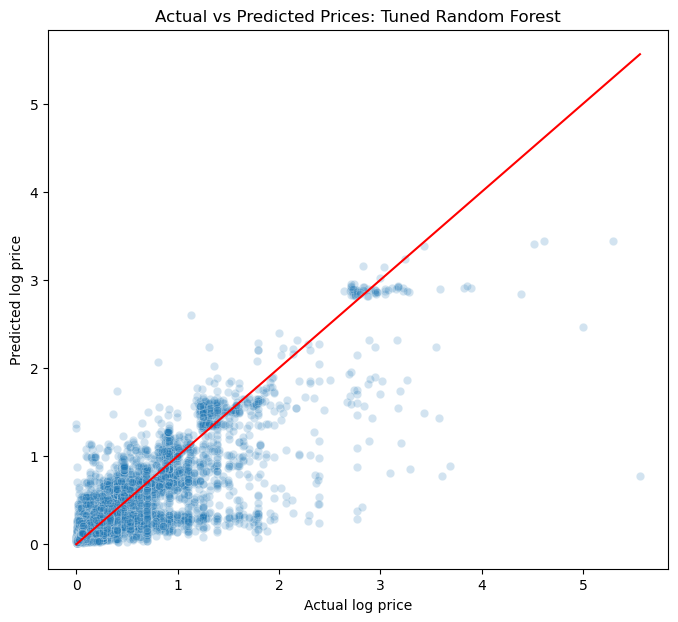

In [72]:
#Lets plot the actual vs the predicted prices 
plt.figure(figsize=(8, 7))

sns.scatterplot(
    x=y_test,
    y=final_predictions,
    alpha=0.2
)

minimum = min(y_test.min(), final_predictions.min())
maximum = max(y_test.max(), final_predictions.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    color="red"
)

plt.title(f"Actual vs Predicted Prices: {final_model_name}")
plt.xlabel("Actual log price")
plt.ylabel("Predicted log price")
plt.show()

In [73]:
#Lets calculate the final test performance 
final_mae_log = mean_absolute_error(
    y_test,
    final_predictions
)

final_r2 = r2_score(
    y_test,
    final_predictions
)

print("Final log-price MAE:", final_mae_log)
print("Final R-squared:", final_r2)

Final log-price MAE: 0.107617270889003
Final R-squared: 0.7036831273877958


In [74]:
#lets Convert predictions back to ETH
actual_price_eth = np.expm1(y_test)
predicted_price_eth = np.expm1(final_predictions)


#lets calculate interepretable errors 
from sklearn.metrics import median_absolute_error

final_mae_eth = mean_absolute_error(
    actual_price_eth,
    predicted_price_eth
)

final_median_error_eth = median_absolute_error(
    actual_price_eth,
    predicted_price_eth
)

print("Mean absolute error in ETH:", final_mae_eth)
print("Median absolute error in ETH:", final_median_error_eth)

Mean absolute error in ETH: 0.26817748629185906
Median absolute error in ETH: 0.06733119610711705


In [75]:
#Lets examine permutation importance 
permutation_table

,Feature,Importance,Variation
8,collection_previous_avg_log_price,0.121423,0.001459
1,collection_activity,0.013479,0.000503
10,buyer_previous_avg_log_price,0.009044,0.000253
9,seller_previous_avg_log_price,0.006297,0.000353
4,previous_token_log_price,0.004158,0.000256
2,seller_activity,0.001496,0.000057
7,token_age_days,0.000167,0.000014
6,days_since_previous_transfer,0.000034,0.000008
5,previous_token_transfers,0.000013,0.000004
0,block_number,0.000000,0.000000


## Interpretation
Compare each model with the median baseline on log-scale MAE and R². ETH errors describe a different scale and can be dominated by outliers. Feature importance measures predictive association, not causation.

## 9. Export results

Aggregate metrics and report go to reports/. Models and row-level predictions go to ignored artifacts/.

In [76]:
#Lets save the fitted model
import joblib
import sklearn

from datetime import datetime, timezone
from pathlib import Path

model_package = {
    "model": final_model,
    "model_name": final_model_name,
    "features": model_features,
    "target": "log_price_eth",
    "inverse_transformation": "np.expm1",
    "sklearn_version": sklearn.__version__,
    "saved_at_utc": datetime.now(timezone.utc).isoformat()
}

model_path = ARTIFACTS / "nft_price_model.joblib"

joblib.dump(model_package, model_path)

print("Model saved to:")
print("artifacts/nft_price_model.joblib")

Model saved to:
artifacts/nft_price_model.joblib


In [77]:
#lets create the final metrics table 
final_train_predictions = final_model.predict(X_train)

final_train_mae = mean_absolute_error(
    y_train,
    final_train_predictions
)

final_train_r2 = r2_score(
    y_train,
    final_train_predictions
)

final_test_mae = mean_absolute_error(
    y_test,
    final_predictions
)

final_test_r2 = r2_score(
    y_test,
    final_predictions
)

final_metrics = pd.DataFrame({
    "Dataset": ["Training", "Testing"],
    "MAE_log_price": [
        final_train_mae,
        final_test_mae
    ],
    "R_squared": [
        final_train_r2,
        final_test_r2
    ]
})

final_metrics

#save it 
final_metrics.to_csv(
    REPORTS / "nft_model_metrics.csv",
    index=False
)

In [78]:
#Lets save feature importance 
permutation_table.to_csv(
    REPORTS / "nft_feature_importance.csv",
    index=False
)

In [79]:
#Lets save actual and predicted prices 
prediction_results = model_df.loc[
    y_test.index,
    [
        "timestamp",
        "transaction_hash",
        "nft_address",
        "token_id",
        "price_eth"
    ]
].copy()

prediction_results["actual_log_price"] = y_test
prediction_results["predicted_log_price"] = final_predictions

prediction_results["predicted_price_eth"] = np.expm1(
    final_predictions
)

prediction_results.to_csv(
    ARTIFACTS / "nft_price_predictions.csv",
    index=False
)

In [80]:
#Lets generate project report
top_features = permutation_table.head(10)

top_features_text = "\n".join(
    f"- {row.Feature}: {row.Importance:.6f}"
    for row in top_features.itertuples()
)

project_report = f"""
# NFT Price Prediction Project

## Project objective

The objective was to identify blockchain transaction factors associated
with NFT prices and develop a model for predicting NFT transaction value.

## Data source

The analysis used an Ethereum NFT SQLite dataset. The main modelling
data came from the transfers table.

The target variable was transaction_value, converted from wei to ETH.
Because NFT prices were highly skewed and contained extreme values,
price_eth was transformed using log(1 + price_eth).

## Data preparation

The data was checked for missing values, duplicates and outliers.
Timestamps were converted from Unix seconds to UTC datetime values.
Transactions were sorted chronologically.

Historical features use earlier rows in timestamp/event-ID order. Same-block
ordering and transaction grouping remain limitations; see README.md.

## Features

The model included:

{chr(10).join("- " + feature for feature in model_features)}

## Models evaluated

The following models were compared:

- Median baseline model
- Multiple linear regression
- Random Forest regression
- Tuned Random Forest regression, where applicable

## Final model

Selected model: {final_model_name}

Training MAE on log-price scale: {final_train_mae:.6f}
Training R-squared: {final_train_r2:.6f}

Testing MAE on log-price scale: {final_test_mae:.6f}
Testing R-squared: {final_test_r2:.6f}

## Most important predictive factors

{top_features_text}

## Interpretation

Compare the model comparison table in the notebook before drawing conclusions
about relative performance. The final forest is chosen using training-data
cross-validation, not test-set MAE. Importance values describe this fitted model.

The difference between training and testing performance indicates the
extent to which the model generalizes to later transactions.

## Limitations

- Transaction value may represent the value of a complete blockchain
  transaction rather than the exact sale price of one NFT.
- The sample covered a limited portion of the complete database.
- The dataset did not include rarity, artwork characteristics, creator
  reputation, social-media interest or cryptocurrency market conditions.
- Feature importance describes predictive usefulness, not causation.
- Historical features must be calculated using only information
  available before each predicted transaction.

## Conclusion

This is an exploratory prediction prototype. Results describe this limited
sample and evaluation protocol, not a validated NFT valuation system.
"""

report_path = REPORTS / "analysis_report.md"

report_path.write_text(
    project_report.strip(),
    encoding="utf-8"
)

print("Report saved to:")
print("reports/analysis_report.md")

Report saved to:
reports/analysis_report.md


In [81]:
conn.close()